# 1. AirComp basics: scenarios, power control and MSE

Over-the-air computation (AirComp) lets $K$ devices transmit **at the same time on the same
resource**, so the multiple-access channel itself computes a sum:

$$y = \sum_{k=1}^K h_k b_k x_k + n, \qquad \hat f = \frac{y}{\sqrt{\eta}} \approx \sum_k x_k .$$

Each device pre-scales its symbol with $b_k$ (phase alignment and power control) and the server
scales by $1/\sqrt\eta$. The **mean squared error** of $\hat f$ is what power control trades off:
misalignment error when devices cannot invert their channel, noise error when $\eta$ is small.

This tutorial covers the `Scenario` object, the four built-in power-control schemes, analytical
vs. signal-level MSE, paired random streams and saving results.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import aircompkit as ac

print("AirCompKit", ac.__version__)

AirCompKit 1.0.1


## Components are named and registered

Every building block (devices, channel, power control, receiver, attack, defence, ...) is a
registered component. `ac.available(kind)` lists them; a scenario refers to them by name or by a
dict with a `"name"` key plus parameters.

In [2]:
for kind in ("devices", "channel", "power_control", "receiver"):
    print(f"{kind:14s}", ac.available(kind))

devices        ['fixed', 'uniform_disc']
channel        ['awgn', 'rayleigh', 'rician']
power_control  ['channel_inversion', 'full_power', 'optimal', 'truncated_inversion']
receiver       ['eigen', 'joint_mmse', 'maxmin', 'sdr']


## A scenario

20 devices uniformly placed in an annulus 10-100 m around a single-antenna server, Rayleigh
fading with path-loss exponent 3, optimal power control (Cao et al. 2020), and the target is the
**mean** of the devices' values.

In [3]:
sc = ac.Scenario(
    devices={"name": "uniform_disc", "K": 20, "p_max": 1.0, "r_min": 10, "r_max": 100},
    channel={"name": "rayleigh", "pathloss": {"exponent": 3.0, "ref_gain_db": -30}},
    power_control="optimal",
    target="mean",
    noise_var=1e-10,
    seed=0,
)
res = sc.run(trials=2000, dim=32)   # 2000 channel draws, 32-dim symbol vectors per draw
for name, (mean, ci) in res.summary().items():
    print(f"{name:14s} {mean:.4g} +/- {ci:.2g}")

mse            0.001256 +/- 3.5e-05
eta            2.173e-10 +/- 4.4e-12
n_active       20 +/- 0
mse_empirical  0.001251 +/- 3.9e-05


`mse` is the analytical MSE given each channel draw; `mse_empirical` simulates the transmission of
random symbols at signal level. They agree within Monte Carlo error, which is one of the checks in
the test suite:

In [4]:
a, e = res["mse"].mean(), res["mse_empirical"].mean()
print(f"analytical {a:.4g}   signal-level {e:.4g}   relative gap {abs(a - e) / a:.2%}")

analytical 0.001256   signal-level 0.001251   relative gap 0.38%


## MSE vs. SNR for the four power-control schemes

Without path loss (unit-mean fading), SNR $= P/\sigma^2$. Changing only `power_control` keeps the
channel draws identical (the seed tree gives every component its own named stream), so the
comparison is **paired**. Truncated channel inversion also has a closed form (Zhu et al. 2020)
that we overlay as a check.

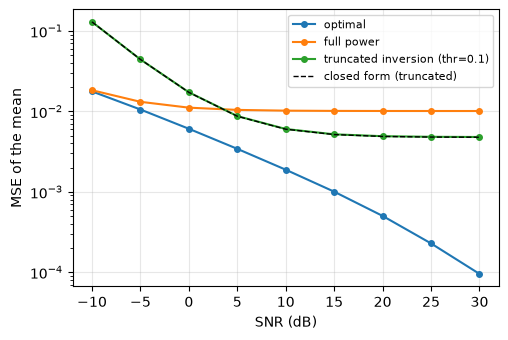

In [5]:
from aircompkit.aircomp.analytic import truncated_inversion_rayleigh_mse

K, THR = 20, 0.1
snr_db = np.arange(-10, 31, 5)
schemes = {"optimal": "optimal", "full_power": "full power",
           "truncated_inversion": f"truncated inversion (thr={THR})"}
curves = {s: [] for s in schemes}
closed = []
for snr in snr_db:
    p = 10 ** (snr / 10)
    for s in schemes:
        pc = {"name": s, "threshold": THR} if s == "truncated_inversion" else s
        r = ac.Scenario(devices={"name": "fixed", "K": K, "p_max": p}, channel="rayleigh",
                        power_control=pc, target="mean", noise_var=1.0, seed=1).run(trials=2000, dim=0)
        curves[s].append(r["mse"].mean())
    closed.append(truncated_inversion_rayleigh_mse([1.0] * K, p, THR, 0.5) / K**2)

fig, ax = plt.subplots(figsize=(5.5, 3.6))
for s, lab in schemes.items():
    ax.semilogy(snr_db, curves[s], "o-", ms=4, label=lab)
ax.semilogy(snr_db, closed, "k--", lw=1, label="closed form (truncated)")
ax.set_xlabel("SNR (dB)"); ax.set_ylabel("MSE of the mean"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

Channel inversion is missing on purpose: under Rayleigh fading its *mean* MSE is infinite, since
the weakest of the $K$ devices sets $\eta$. Its median is finite, and a paired comparison shows the
optimal scheme is never worse on any single channel draw:

In [6]:
base = dict(devices={"name": "fixed", "K": K, "p_max": 10.0}, channel="rayleigh",
            target="mean", noise_var=1.0, seed=1)
opt = ac.Scenario(**base, power_control="optimal").run(trials=2000, dim=0)["mse"]
for s in ("channel_inversion", "full_power", "truncated_inversion"):
    other = ac.Scenario(**base, power_control=s).run(trials=2000, dim=0)["mse"]
    print(f"{s:20s} median {np.median(other):9.4g}   optimal <= it on every draw: "
          f"{bool(np.all(opt <= other * (1 + 1e-9)))}")

channel_inversion    median  0.003502   optimal <= it on every draw: True
full_power           median   0.01011   optimal <= it on every draw: True
truncated_inversion  median   0.00625   optimal <= it on every draw: True


## Configs and results are files

A scenario round-trips through a plain dict / YAML file, and a `Result` saves its arrays (`.npz`)
next to a `.json` with the full config and package versions, so every number can be traced back
to the exact setup.

In [7]:
import json, tempfile
from pathlib import Path

tmp = Path(tempfile.mkdtemp())
sc.to_yaml(tmp / "scenario.yaml")
print((tmp / "scenario.yaml").read_text())
again = ac.Scenario.from_yaml(tmp / "scenario.yaml")
assert np.allclose(again.run(trials=200, dim=0)["mse"], sc.run(trials=200, dim=0)["mse"])

npz, js = res.save(tmp / "demo")
print(json.dumps(json.loads(js.read_text())["meta"], indent=1)[:400])

devices:
  name: uniform_disc
  K: 20
  p_max: 1.0
  r_min: 10
  r_max: 100
channel:
  name: rayleigh
  pathloss:
    exponent: 3.0
    ref_distance: 1.0
    ref_gain_db: -30
    shadowing_db: 0.0
  n_rx: 1
  corr: 0.0
power_control:
  name: optimal
receiver:
  name: maxmin
  iters: 400
  random_inits: 24
  step: 0.5
  temp_start: 1.0
  temp_end: 0.005
  seed: 0
impairments:
  csi_error: 0.0
  phase_error_std: 0.0
target:
  name: mean
noise_var: 1.0e-10
symbols: real
seed: 0

{
 "trials": 2000,
 "dim": 32,
 "batch": 1024,
 "aircompkit": "1.0.1",
 "numpy": "2.5.5",
 "python": "3.13.14"
}


The same scenario runs from the command line: `aircompkit run configs/rayleigh_optimal.yaml --out results/run1`.
Next: [multi-antenna receivers and impairments](02_multi_antenna_and_impairments.ipynb).